In [1]:
# import required modules 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import cooltools
import bioframe
import cooler

from cooltools.api.eigdecomp import eigs_cis
import HMMC


In [2]:
assembly = 'hg38'

In [3]:
# specify cooler and fasta storage locations
# H9 cooler (4DNFIT5YVTLO) is not on this server; using GM12878 instead
cooler_file = '/gladstone/engelhardt/lab/lchumpitaz/hi-c/mcools/4DNFIXP4QG5B.mcool'
fasta_file='/gladstone/engelhardt/lab/lchumpitaz/hi-c/hg38.fa'

In [4]:
cooler.fileops.list_coolers(cooler_file)

['/resolutions/1000',
 '/resolutions/2000',
 '/resolutions/5000',
 '/resolutions/10000',
 '/resolutions/25000',
 '/resolutions/50000',
 '/resolutions/100000',
 '/resolutions/250000',
 '/resolutions/500000',
 '/resolutions/1000000',
 '/resolutions/2500000',
 '/resolutions/5000000',
 '/resolutions/10000000']

In [5]:
# load cooler, obtain bin table
resolution = 25000
c = cooler.Cooler(cooler_file+'::resolutions/'+str(resolution))
chromsizes = c.chromsizes      
bins = c.bins()[:]

In [6]:
# generate binned dataframe of GC content
fasta_records = bioframe.load_fasta(fasta_file)
gc_table = bioframe.frac_gc(bins, fasta_records)
# cooltools uses columns[:4] as the value: pass a clean 4-column GC track
gc_table = gc_table[['chrom', 'start', 'end', 'GC']]

In [7]:
regions = HMMC.chrom_regions(assembly, chromsizes)
regions

[('chr1', 0, np.int32(248956422)),
 ('chr2', 0, np.int32(242193529)),
 ('chr3', 0, np.int32(198295559)),
 ('chr4', 0, np.int32(190214555)),
 ('chr5', 0, np.int32(181538259)),
 ('chr6', 0, np.int32(170805979)),
 ('chr7', 0, np.int32(159345973)),
 ('chr8', 0, np.int32(145138636)),
 ('chr9', 0, np.int32(138394717)),
 ('chr10', 0, np.int32(133797422)),
 ('chr11', 0, np.int32(135086622)),
 ('chr12', 0, np.int32(133275309)),
 ('chr13', 0, np.int32(114364328)),
 ('chr14', 0, np.int32(107043718)),
 ('chr15', 0, np.int32(101991189)),
 ('chr16', 0, np.int32(90338345)),
 ('chr17', 0, np.int32(83257441)),
 ('chr18', 0, np.int32(80373285)),
 ('chr19', 0, np.int32(58617616)),
 ('chr20', 0, np.int32(64444167)),
 ('chr21', 0, np.int32(46709983)),
 ('chr22', 0, np.int32(50818468))]

In [8]:
# specify regions as autosomes, obtain cis eigenvectors
smooth = False
OE_log = False
view_df = pd.DataFrame([(chrom, 0, int(chromsizes[chrom])) for chrom in chromsizes.index
                       if chrom.replace('chr', '').isdigit()],
                      columns=['chrom', 'start', 'end'])
view_df['name'] = view_df['chrom']
cis_val, cis_eig = eigs_cis(
                c,
                phasing_track=gc_table,
                view_df=view_df,
                n_eigs=3,
                ignore_diags = 2, clip_percentile=99)
cis_eig = cis_eig.iloc[ np.array([i.isdigit() for i in cis_eig.chrom.str.replace('chr','').values])]

In [9]:
def get_bics(build_model, get_bic, min_model, max_model, data):
    models = [build_model(data, n_components, constrain_transmat=False) for n_components in range(min_model, max_model + 1)]
    bics = [get_bic(model, data) for model in models]
    return bics, models

In [10]:
# get segmentation using HMMC
hmm_track, BIC_dict = HMMC.get_segmentation(cis_eig, 
                                  state_list= ["binary", "HMM2","HMM3", "HMM3P", "HMM4", "HMM5"], 
                                  regions=regions, return_BIC_dict=True, verbose=True)

generating segmentation for binary
generating segmentation for HMM2


generating segmentation for HMM3


generating segmentation for HMM3P
generating segmentation for HMM4


generating segmentation for HMM5


In [11]:
bics = [(key, vals) for key, vals in BIC_dict.items()]
bics.sort(key=lambda x: x[0])
bics_vals = np.array([vals for key, vals in bics])

In [12]:
bics_vals

array([ 37414.64197475, -29283.79594915, -71460.75518156, -99702.76562587])

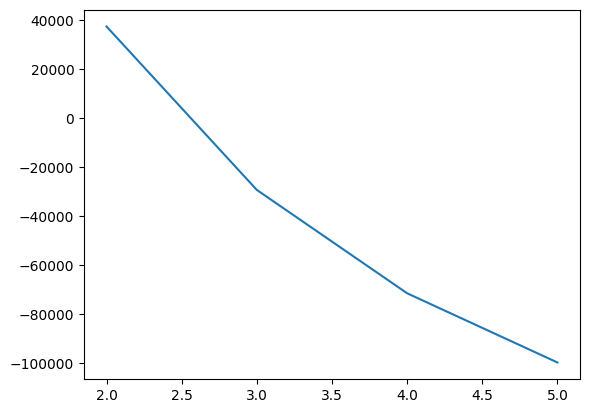

In [13]:
plt.plot(np.arange(2, len(bics_vals)+2), bics_vals)

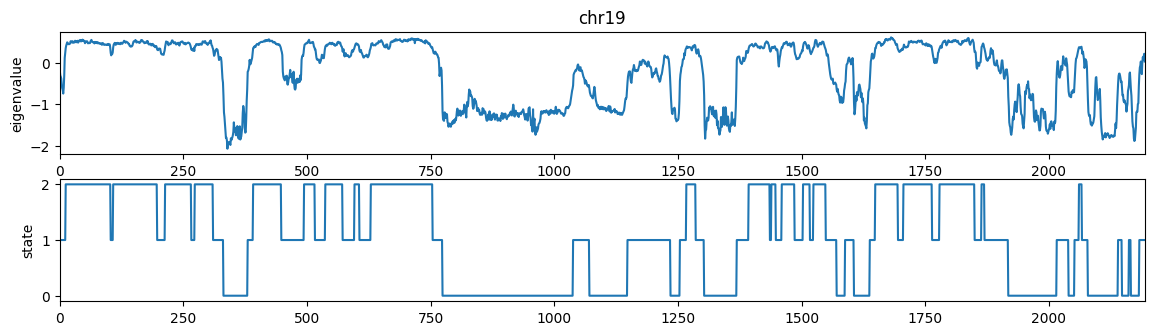

In [14]:
# visualize eigenvector and HMM3P segmentation for chromosome 19
# HMM3P_nums_to_names =  {0:'B', 1:'M_{bb}', 2:'M', 3:'M_{aa}', 4:'A'}
# HMM2_nums_to_names  =  {0:'B', 1:'A'}

fig = plt.figure(figsize=(14, 3.5))

ax1 = plt.subplot(211)
chrom = 'chr19'
mask = (~hmm_track['E1'].isna()) & (hmm_track.chrom == chrom)
y1 = hmm_track[mask]['E1'].values
ax1.plot(y1)
ax1.margins(x=0)
ax1.set_ylabel('eigenvalue')
plt.title(chrom)

# plt.figure(figsize=(14, 1.5))
ax2 = plt.subplot(212)
y2 = hmm_track[mask]['HMM3'].values 
ax2.plot(y2)
ax2.set_ylabel('state')
ax2.margins(x=0)

In [15]:
hmm_track

,chrom,start,end,KR,VC,VC_SQRT,weight,E1,E2,E3,binary,HMM2,HMM3,HMM3P,HMM4,HMM5
0,chr1,0,25000,NaN,0.002548,0.034406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chr1,25000,50000,NaN,0.001826,0.029127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chr1,50000,75000,NaN,0.019703,0.095678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,chr1,75000,100000,NaN,0.004713,0.046797,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,chr1,100000,125000,NaN,0.019023,0.094014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115004,chr22,50700000,50725000,0.919536,1.621853,0.902310,0.003883,-0.273457,0.576923,0.259086,0.0,0.0,1.0,2.0,2.0,2.0
115005,chr22,50725000,50750000,0.934506,1.581227,0.890937,0.003675,-0.295694,0.546716,0.406209,0.0,0.0,1.0,2.0,2.0,2.0
115006,chr22,50750000,50775000,0.501871,0.752977,0.614810,0.006504,-0.140475,0.489133,0.184162,0.0,0.0,1.0,2.0,2.0,2.0
115007,chr22,50775000,50800000,0.347564,0.453748,0.477263,0.009642,-0.068095,0.510889,0.228893,0.0,0.0,1.0,2.0,2.0,2.0


In [16]:
segmentation = 'HMM3P'
bed_track = HMMC.track_to_bed(hmm_track, segmentation)
bed_track.head()                                                                                                                                                                                                                          

,chrom,start,end,name,score,strand,thickStart,thickEnd,rgb
0,chr1,0,25000,N,0,-,0,25000,"248,248,248"
1,chr1,25000,50000,N,0,-,25000,50000,"248,248,248"
2,chr1,50000,75000,N,0,-,50000,75000,"248,248,248"
3,chr1,75000,100000,N,0,-,75000,100000,"248,248,248"
4,chr1,100000,125000,N,0,-,100000,125000,"248,248,248"


In [17]:
import os
out_dir = '../outputs/notebooks/GM12878'
os.makedirs(out_dir, exist_ok=True)
hmm_track.to_csv(out_dir+'/GM12878_'+assembly+'_'+segmentation+'_'+str(resolution)+'.tsv', sep='\t', index=False)
bed_track.to_csv(out_dir+'/GM12878_'+assembly+'_'+segmentation+'_'+str(resolution)+'.bed', sep='\t', index=False, header=False)